# Partie 4 : Système hybride avec rejet de l'inconnu

Un classifieur softmax répond toujours une maladie, même devant une image qu'il ne connaît pas. Ici on teste trois façons de répondre « inconnu » :

1. **MSP** : le classifieur de la partie 2 rejette quand sa probabilité maximale (softmax) est trop faible ;
2. **Auto-encodeur** : on rejette quand l'erreur de reconstruction de l'AE de la partie 3 est trop grande ;
3. **Hybride** : on combine les deux signaux.

Protocole « classe inconnue » (leave-one-class-out) : la maladie M est retirée du classifieur (train et validation). L'auto-encodeur n'a, lui, jamais vu de maladie. À l'évaluation, les images de M doivent être déclarées « inconnu ». Tous les seuils sont fixés sur la validation des classes connues, jamais sur le test.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

from src import config as C
from src import data as D
from src.models import TLModel, tl_optimizer, build_ae, load_classifier
from src.train import fit, export_checkpoint
from src.metrics import predict, upsert_summary, savefig

C.set_seed(42)
dev = C.DEVICE
print(C.describe_env())

Python 3.12.15, torch 2.14.1+cu126, torchvision 0.29.1+cu126
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 2060 with Max-Q Design
CPU : AMD Ryzen 9 4900HS with Radeon Graphics (16 coeurs logiques)


## 1. Données et protocole

- `M` est la maladie retirée, définie dans `config.py` (la mosaïque, la classe la plus rare : 373 images). Les 9 autres classes sont les classes **connues**.
- Validation des classes connues : sert à fixer tous les seuils. Test des classes connues et test de M : évaluation, une seule fois.
- Jeu hors-distribution (`data/ood.csv`) : on utilise la moitié `eval`.

In [2]:
df = D.load_splits()
M, KNOWN = C.UNKNOWN_CLASS, D.KNOWN_CLASSES
print("Maladie M retirée :", D.short(M), "|", len(KNOWN), "classes connues")

ood = pd.read_csv(C.OOD_CSV)
ood["present"] = [C.resolve(p).exists() for p in ood["path"]]
print(ood.groupby(["source", "ood_split"])["present"].agg(images_presentes="sum", total="count"))

sets = {"val_connues": D.subset(df, split="val", classes=KNOWN),
        "test_connues": D.subset(df, split="test", classes=KNOWN),
        "test_M": D.subset(df, split="test", classes=[M]),
        "ood": ood[(ood["ood_split"] == "eval") & ood["present"]].reset_index(drop=True)}
print({k: len(v) for k, v in sets.items()})

Maladie M retirée : Mosaic_virus | 9 classes connues
                               images_presentes  total
source              ood_split                         
plantdoc            eval                     62     62
plantvillage_autres calib                     0    273
                    eval                      0    315
{'val_connues': 2667, 'test_connues': 2670, 'test_M': 55, 'ood': 62}


## 2. Classifieur sans M

Même modèle et même stratégie que la recommandation de la partie 2 (MobileNetV3-Large, dernier tiers dégelé, 5 époques), entraîné sur les 9 classes connues.

In [3]:
NORM, SIZE = D.norm_stats("imagenet"), C.TL_SIZE
CKPT = C.CKPT_DIR / "clf_sans_M.pt"

if not CKPT.exists():
    loaders9 = D.clf_loaders(df, KNOWN, SIZE, NORM, batch_size=64)
    assert M not in set(loaders9["train"].dataset.df["class"])
    poids = D.class_weights(loaders9["train"].dataset.labels, len(KNOWN)).to(dev)
    C.set_seed(42)
    model9 = TLModel("mobilenet_v3_large", len(KNOWN), "last_third").to(dev)
    meta = {"arch": "mobilenet_v3_large", "strategy": "last_third", "classes": KNOWN, "size": SIZE, "norm": NORM}
    h9 = fit(model9, loaders9, C.ep(5), tl_optimizer(model9, lr_head=0.001, lr_backbone=0.0001),
             nn.CrossEntropyLoss(weight=poids), "clf_sans_M", meta)
    export_checkpoint("clf_sans_M", "clf_sans_M.pt")
    print("Best validation F1 (9 classes) :", round(h9["val_f1"].max(), 4))

clf, meta = load_classifier(CKPT)
assert meta["classes"] == KNOWN and M not in meta["classes"]
print("Loaded Classifier :", meta["arch"], meta["strategy"], "|", len(meta["classes"]), "classes")

ae = build_ae(16).to(dev)
ae.load_state_dict(torch.load(C.CKPT_DIR / "ae_best.pt", map_location=dev))
ae.eval()
print("Loaded Auto-Encoder : k = 16 (partie 3)")

Loaded Classifier : mobilenet_v3_large last_third | 9 classes
Loaded Auto-Encoder : k = 16 (partie 3)


## 3. Les deux scores de chaque image

- **MSP** : probabilité softmax maximale du classifieur (224×224). Proche de 1 = confiant.
- **Erreur AE** : MSE de reconstruction de l'AE (64×64, pixels dans [0, 1]).
- On garde aussi la classe prédite, pour mesurer l'accuracy sur les images acceptées.

In [4]:
@torch.no_grad()
def ae_errors(paths):
    X = torch.from_numpy(np.array(D.load_cache([C.resolve(p) for p in paths], C.AE_SIZE))).permute(0, 3, 1, 2).float().div(255).to(dev)
    return torch.cat([((ae(X[i:i + 256]) - X[i:i + 256]) ** 2).mean(dim=(1, 2, 3)) for i in range(0, len(X), 256)]).cpu().numpy()

def compute_scores(d):
    ds = D.LeafDataset(d, SIZE, D.get_transform("clf", False, NORM), KNOWN, preload=False)
    y, pred, prob = predict(clf, D.make_loader(ds, 128))
    return pd.DataFrame({"path": d["path"].values, "y": y, "pred": pred, "msp": prob.max(1), "err": ae_errors(d["path"])})

S = {name: compute_scores(d) for name, d in sets.items() if len(d)}
for name, s in S.items():
    print(f"{name:13s} n={len(s):5d}  MSP médian {s.msp.median():.4f}  erreur AE médiane {s.err.median():.5f}")
acc_known = (S["test_connues"].y == S["test_connues"].pred).mean()
print(f"Accuracy du classifieur sur le test des classes connues (sans rejet) : {acc_known:.4f}")

val_connues   n= 2667  MSP médian 1.0000  erreur AE médiane 0.00902
test_connues  n= 2670  MSP médian 1.0000  erreur AE médiane 0.00922
test_M        n=   55  MSP médian 0.9097  erreur AE médiane 0.00645
ood           n=   62  MSP médian 0.9934  erreur AE médiane 0.02891
Accuracy du classifieur sur le test des classes connues (sans rejet) : 0.9959


## 4. Les trois règles de rejet et leurs seuils (validation)

On accepte de rejeter à tort **5 %** des feuilles connues de la validation (`ALPHA = 0.05`), pour les trois systèmes :

- **MSP** : rejet si `MSP < τ₁`, avec τ₁ = percentile 5 du MSP des classes connues.
- **AE** : rejet si `erreur > τ₂`, avec τ₂ = percentile 95 de l'erreur des classes connues (les 9 classes, maladies connues comprises ; le seuil de la partie 3 était réglé sur les feuilles saines seules et rejetterait trop de maladies connues).
- **Hybride** : chaque score est d'abord ramené entre 0 et 1 par sa fonction de répartition sur la validation des classes connues (« quelle part des classes connues est moins suspecte que cette image ? »), puis `score = max(score_MSP, score_AE)`, et on rejette au-dessus du percentile 95. C'est un « rejet si l'un des deux signaux est inhabituel », sans que l'un des deux écrase l'autre par son échelle.

Pour comparer les trois systèmes, chaque règle est ramenée à un **score d'inconnu** (grand = suspect) : `1 - MSP`, `erreur`, `score hybride`.

In [5]:
ALPHA = 0.05
val = S["val_connues"]

def ecdf(ref):
    ref = np.sort(ref)
    return lambda s: np.searchsorted(ref, s, side="right") / len(ref)

f_msp, f_err = ecdf(1 - val.msp.values), ecdf(val.err.values)
unk_score = {"MSP": lambda s: 1 - s.msp.values,
             "AE": lambda s: s.err.values,
             "Hybride": lambda s: np.maximum(f_msp(1 - s.msp.values), f_err(s.err.values))}
tau = {name: float(np.percentile(f(val), 100 * (1 - ALPHA))) for name, f in unk_score.items()}

print(f"τ₁ (MSP < {1 - tau['MSP']:.4f}) | τ₂ (erreur > {tau['AE']:.5f}) | hybride : score > {tau['Hybride']:.3f}")
for name, f in unk_score.items():
    print(f"{name:8s} rejet à tort des connues, validation : {(f(val) > tau[name]).mean():.3f}")

τ₁ (MSP < 0.9893) | τ₂ (erreur > 0.02080) | hybride : score > 0.975
MSP      rejet à tort des connues, validation : 0.050
AE       rejet à tort des connues, validation : 0.050
Hybride  rejet à tort des connues, validation : 0.050


## 5. Les deux signaux sur les images

Chaque point est une image. L'axe horizontal est le MSP (à gauche = classifieur peu sûr), l'axe vertical l'erreur de reconstruction (en haut = mal reconstruite). Les traits pointillés sont les seuils τ₁ et τ₂ de la validation : la zone de rejet est à gauche de τ₁ ou au-dessus de τ₂.

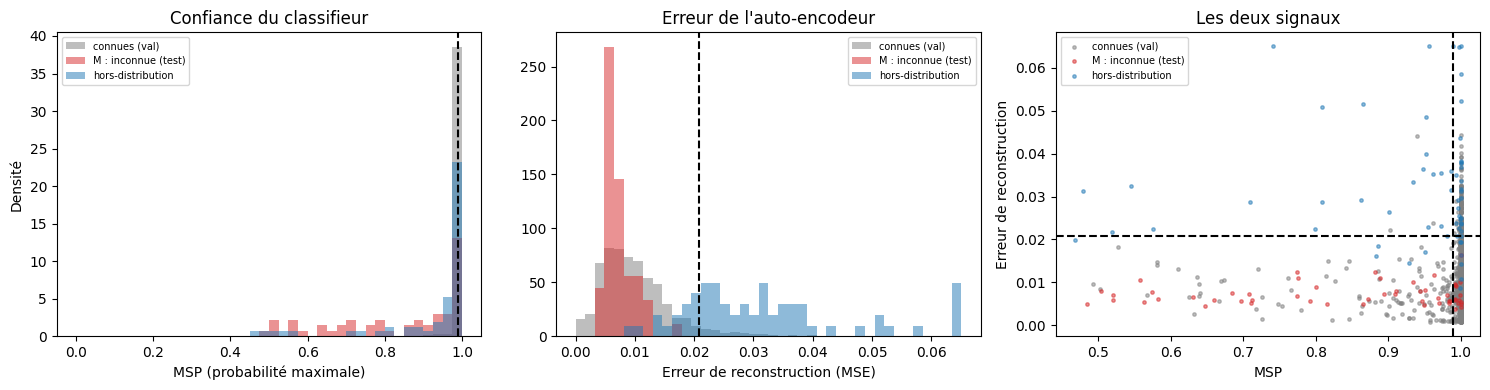

Classe prédite pour les images de M (le classifieur ne connaît pas M) :
pred
Septoria_leaf_spot    34
Spider_mites           7
Leaf_Mold              6
Early_blight           4
Yellow_Leaf_Curl       3
Target_Spot            1


In [6]:
groups = [("val_connues", "connues (val)", "tab:gray"), ("test_M", "M : inconnue (test)", "tab:red"), ("ood", "hors-distribution", "tab:blue")]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for key, lab, col in groups:
    if key not in S: continue
    ax[0].hist(S[key].msp, np.linspace(0, 1, 41), alpha=.5, density=True, label=lab, color=col)
    hi = np.percentile(S["val_connues"].err, 99.5) * 2
    ax[1].hist(np.clip(S[key].err, 0, hi), np.linspace(0, hi, 41), alpha=.5, density=True, label=lab, color=col)
    ax[2].scatter(S[key].msp, np.clip(S[key].err, 0, hi), s=6, alpha=.5, label=lab, color=col)
ax[0].axvline(1 - tau["MSP"], ls="--", c="k"); ax[0].set_xlabel("MSP (probabilité maximale)"); ax[0].set_ylabel("Densité")
ax[1].axvline(tau["AE"], ls="--", c="k"); ax[1].set_xlabel("Erreur de reconstruction (MSE)")
ax[2].axvline(1 - tau["MSP"], ls="--", c="k"); ax[2].axhline(tau["AE"], ls="--", c="k")
ax[2].set_xlabel("MSP"); ax[2].set_ylabel("Erreur de reconstruction")
for a, t in zip(ax, ["Confiance du classifieur", "Erreur de l'auto-encodeur", "Les deux signaux"]):
    a.set_title(t); a.legend(fontsize=7)
plt.tight_layout(); savefig("04_scores_msp_ae.png"); plt.show()

print("Classe prédite pour les images de M (le classifieur ne connaît pas M) :")
print(S["test_M"].pred.map(lambda i: D.short(KNOWN[i])).value_counts().to_string())

## 6. Comparaison des trois systèmes sur le test

Pour chaque système, aux seuils fixés sur la validation :

- **AUROC connu vs inconnu** (M) : qualité du score, indépendamment du seuil ;
- **rejet de M** : part des images de M déclarées « inconnu » (à maximiser) ;
- **rejet à tort des connues** : part des feuilles connues rejetées (attendu ~5 %) ;
- **accuracy sur les connues acceptées** : accuracy du classifieur sur les feuilles connues que le système accepte.

In [7]:
def evaluate(name):
    f, t = unk_score[name], tau[name]
    kn, um = S["test_connues"], S["test_M"]
    accepted = f(kn) <= t
    row = {"système": name,
           "AUROC (M)": roc_auc_score(np.r_[np.zeros(len(kn)), np.ones(len(um))], np.r_[f(kn), f(um)]),
           "rejet de M": (f(um) > t).mean(),
           "rejet à tort des connues": 1 - accepted.mean(),
           "accuracy connues acceptées": (kn.y.values == kn.pred.values)[accepted].mean()}
    if "ood" in S:
        oo = S["ood"]
        row["AUROC (hors-distribution)"] = roc_auc_score(np.r_[np.zeros(len(kn)), np.ones(len(oo))], np.r_[f(kn), f(oo)])
        row["rejet hors-distribution"] = (f(oo) > t).mean()
    return row

res = pd.DataFrame([evaluate(n) for n in unk_score]).set_index("système")
print(f"Accuracy sans rejet (connues) : {acc_known:.4f}")
res.round(3)

Accuracy sans rejet (connues) : 0.9959


,AUROC (M),rejet de M,rejet à tort des connues,accuracy connues acceptées,AUROC (hors-distribution),rejet hors-distribution
système,,,,,,
MSP,0.962,0.745,0.043,1.000,0.855,0.468
AE,0.343,0.000,0.050,0.996,0.958,0.823
Hybride,0.930,0.545,0.045,1.000,0.953,0.726


### Courbes ROC et compromis couverture / précision

- **ROC** : connu vs inconnu (M), pour les trois scores.
- **Couverture / précision, connues seules** : en faisant varier le seuil, quelle part des feuilles connues le système accepte (couverture), et quelle accuracy il atteint sur celles-ci.
- **Couverture / précision, connues et M** : même chose en ajoutant les images de M au test. Une image de M acceptée est donc forcément une erreur. La précision est la part de réponses correctes parmi les images acceptées.

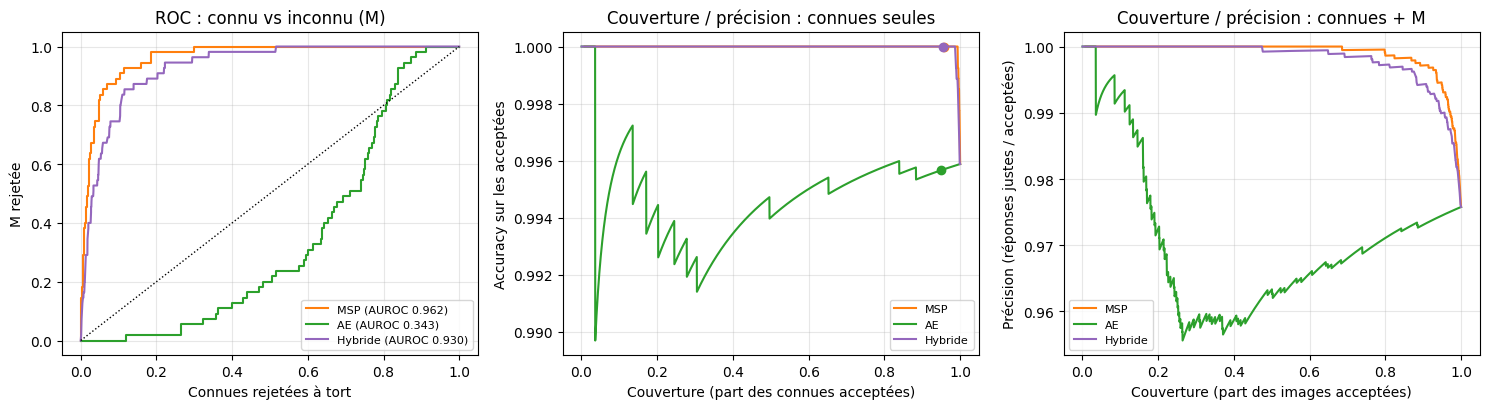

In [8]:
kn, um = S["test_connues"], S["test_M"]
ok_kn = kn.y.values == kn.pred.values
colors = {"MSP": "tab:orange", "AE": "tab:green", "Hybride": "tab:purple"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for name, f in unk_score.items():
    sk, su = f(kn), f(um)
    y_unk = np.r_[np.zeros(len(sk)), np.ones(len(su))]
    fpr, tpr, _ = roc_curve(y_unk, np.r_[sk, su])
    ax[0].plot(fpr, tpr, label=f"{name} (AUROC {roc_auc_score(y_unk, np.r_[sk, su]):.3f})", c=colors[name])
    cov_k, acc_k, cov_a, acc_a = [], [], [], []
    for t in np.unique(np.r_[sk, su]):
        a, n_unk = sk <= t, (su <= t).sum()
        if a.sum() == 0: continue
        cov_k.append(a.mean()); acc_k.append(ok_kn[a].mean())
        cov_a.append((a.sum() + n_unk) / (len(sk) + len(su))); acc_a.append(ok_kn[a].sum() / (a.sum() + n_unk))
    ax[1].plot(cov_k, acc_k, label=name, c=colors[name]); ax[2].plot(cov_a, acc_a, label=name, c=colors[name])
    r = res.loc[name]
    ax[1].plot(1 - r["rejet à tort des connues"], r["accuracy connues acceptées"], "o", c=colors[name])
ax[0].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].set_xlabel("Connues rejetées à tort"); ax[0].set_ylabel("M rejetée"); ax[0].set_title("ROC : connu vs inconnu (M)")
ax[1].set_xlabel("Couverture (part des connues acceptées)"); ax[1].set_ylabel("Accuracy sur les acceptées"); ax[1].set_title("Couverture / précision : connues seules")
ax[2].set_xlabel("Couverture (part des images acceptées)"); ax[2].set_ylabel("Précision (réponses justes / acceptées)"); ax[2].set_title("Couverture / précision : connues + M")
for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); savefig("04_roc_couverture_precision.png"); plt.show()

**Interprétation (rejet de M)**

- *MSP.* C'est le meilleur système pour M : AUROC 0,962, 74,5 % des images de M rejetées (41 sur 55) pour 4,3 % de feuilles connues rejetées à tort. Le classifieur ne connaît pas M mais ne sait pas non plus « se taire » : il range 34 des 55 images de M dans Septoria_leaf_spot, avec une confiance plus basse que d'habitude (MSP médian 0,91 contre 1,00 pour les connues). Il reste 25 % des images de M acceptées, donc diagnostiquées à tort avec aplomb. Le MSP des connues est saturé près de 1 : le seuil (0,989) se joue dans un intervalle très étroit.

- *Auto-encodeur.* AUROC 0,343 (sous le hasard) et 0 % de M rejetée : l'erreur de reconstruction de M (médiane 0,0065) est **plus faible** que celle des feuilles connues (0,0092). L'AE ordonne M comme plus « normale » que les connues. L'explication probable, non testée ici, est que les feuilles de mosaïque sont compactes et lisses, donc faciles à reconstruire pour un AE flou à k = 16 ; cela concorde avec le rappel de 0,02 de la mosaïque en partie 3. C'est la limite « reconstruction trop bonne » : l'erreur mesure la complexité de l'image plus que son caractère inconnu.

- *Hybride.* AUROC 0,930 et 54,5 % de M rejetée : moins bon que le MSP seul pour M (environ 20 points de rejet en moins). Avec la règle « rejet si l'un des deux signaux est inhabituel », une partie du budget de 5 % de rejets à tort est dépensée sur le signal de l'AE, qui pour M n'apporte que du bruit.

- *Accuracy sur les connues acceptées.* 1,000 pour le MSP et l'hybride, 0,996 pour l'AE, contre 0,9959 sans rejet : rejeter 4 à 5 % des connues apporte très peu, car le classifieur est déjà à 99,6 %. Le gain du rejet se voit surtout quand on ajoute M (courbe de droite) : la précision du MSP et de l'hybride reste proche de 1 jusqu'à une couverture d'environ 0,8, alors que la courbe de l'AE passe sous la précision sans rejet (0,976), car l'AE retire des feuilles connues, pas M.

- *Limite.* M est une seule maladie, avec 55 images de test : le taux de rejet de M a un intervalle de confiance d'environ ±12 points, et nous n'avons qu'une graine. Les écarts entre MSP et hybride (20 points) dépassent cette marge, mais pas de beaucoup.

## 7. Jeu hors-distribution (feuilles de tomate au champ, autres plantes, ...)

Les mêmes seuils (fixés sur la validation des connues) sont appliqués aux images qui ne sont pas des feuilles de tomate de laboratoire. Ici, le taux de rejet est le critère principal : toutes ces images devraient être rejetées.

In [9]:
if "ood" in S:
    oo = sets["ood"]
    out = []
    for name, f in unk_score.items():
        rej = f(S["ood"]) > tau[name]
        out.append(pd.DataFrame({"système": name, "source": oo["source"], "catégorie": oo["category"], "rejetée": rej}))
    out = pd.concat(out)
    print(out.groupby(["système", "source"])["rejetée"].agg(rejet="mean", n="count").round(3).to_string())
else:
    print("Aucune image hors-distribution présente sur cette machine.")

                  rejet   n
système source             
AE      plantdoc  0.823  62
Hybride plantdoc  0.726  62
MSP     plantdoc  0.468  62


**Interprétation (hors-distribution)**

Seules les 62 photos de tomate au champ (PlantDoc) sont présentes sur cette machine : les autres plantes de PlantVillage et nos propres photos ne le sont pas, donc cette partie est incomplète et sera à refaire avec tout le jeu.

- Sur ces photos, l'ordre est inversé : l'AE rejette 82,3 % des images (AUROC 0,958), l'hybride 72,6 % (0,953) et le MSP seulement 46,8 % (0,855). Le classifieur reste sûr de lui sur des feuilles prises au champ (MSP médian 0,993) : le softmax est saturé et affirme avec aplomb une maladie sur des images éloignées de son entraînement. L'AE voit le changement de fond et d'éclairage (erreur médiane 0,029 contre 0,009).

- Ce que mesure l'AE ici est l'écart de fond et de conditions de prise de vue, pas la maladie : c'est utile pour refuser une photo hors laboratoire, mais cela confirme que l'AE est sensible au fond (biais de fond, partie 6).

- *Robustesse.* Aucun système n'est le meilleur partout : le MSP est le meilleur pour M mais faible hors-distribution (46,8 %), l'AE est le meilleur hors-distribution mais ne rejette aucune image de M (0 %). L'hybride est le seul qui ne s'effondre sur aucun des deux jeux (54,5 % pour M, 72,6 % hors-distribution) : c'est le plus robuste au sens du pire cas, sans être le meilleur sur chacun.

In [10]:
# Enregistrement : lignes du tableau récapitulatif et scores par image (réutilisables en parties 6 et 7)
for name in unk_score:
    r = res.loc[name]
    row = {"experiment": f"P4_{name}", "partie": 4, "modele": f"{name} (M = {D.short(M)})",
           "hyperparametres": f"rejet à tort des connues fixé à {ALPHA:.0%} sur la validation",
           "auroc_M": r["AUROC (M)"], "rejet_M": r["rejet de M"], "rejet_connues": r["rejet à tort des connues"],
           "acc_connues_acceptees": r["accuracy connues acceptées"]}
    if "AUROC (hors-distribution)" in r:
        row.update({"auroc_ood": r["AUROC (hors-distribution)"], "rejet_ood": r["rejet hors-distribution"]})
    upsert_summary(row)

pd.concat([s.assign(ensemble=name, msp_unk=unk_score["MSP"](s), ae_err=unk_score["AE"](s), hybride=unk_score["Hybride"](s))
           for name, s in S.items()]).to_csv(C.SCORES_CSV, index=False)
C.save_json({"alpha": ALPHA, "M": M, "tau_msp": 1 - tau["MSP"], "tau_ae": tau["AE"], "tau_hybride": tau["Hybride"]},
            C.RESULTS / "thresholds_open_set.json")
print("summary.csv (3 lignes P4_*), scores.csv, thresholds_open_set.json")

summary.csv (3 lignes P4_*), scores.csv, thresholds_open_set.json


## Conclusion de la partie 4

- Les deux signaux sont **complémentaires** : le classifieur repère les maladies proches de ce qu'il connaît mais mal classées (M, rejetée à 74,5 % par le MSP), l'AE repère les images éloignées de l'entraînement (photos de terrain, 82,3 %) mais pas M, qu'il trouve « trop facile » à reconstruire. L'AE seul ne suffit donc pas, et le softmax seul non plus : il affiche une confiance élevée sur des photos de terrain.

- Le système **hybride** (rejet si l'un des deux signaux est inhabituel, seuil fixé à 5 % de rejets à tort sur la validation) est le choix prudent : il perd 20 points sur M par rapport au MSP, mais en gagne 26 hors-distribution et n'est jamais en échec complet.

- *Limites.* Une seule maladie M (la mosaïque virus), 55 images de test ; jeu hors-distribution réduit à 62 photos d'une seule source ; la règle hybride est choisie a priori. Avec M = Septoria ou Leaf_Mold, qui ont des taches, l'AE pourrait se comporter autrement.